# Colab 환경에서 실행 시 환경 설정

구글 드라이브의 폴더와 구글 코랩 폴더 연결

In [93]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [94]:
# 현재 경로 확인
!pwd

/content/Mecab-ko-for-Google-Colab


In [95]:
# drive/MyDrive/himedia 경로로 변경
%cd drive/MyDrive/himedia/test

[Errno 2] No such file or directory: 'drive/MyDrive/himedia/test'
/content/Mecab-ko-for-Google-Colab


### 코랩에서 한국어 표시하기

In [130]:
!pip install koreanize-matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 91.9 MB/s eta 0:00:00


In [131]:
import koreanize_matplotlib

# 🔖 자연어 처리 기초

<a id="lecture_index"></a>
# 수업 목차

[1. 자연어 처리 개요](#one)<br>
- 자연어 처리란?
- 자연어 처리의 발전 흐름
- 자연어 처리 작업 분류

[2. 자연어 데이터의 특징 및 처리 과정](#two)<br>
- 자연어 데이터란?
- 텍스트 데이터의 특징
- 텍스트 데이터의 처리 과정

[3. 규칙기반 자연어 처리](#three)<br>
- 형태소 분석
- 토큰화
- 정규화
- 불용어 제거
- 표제어 추출
- 어간 추출
- 규칙 기반 NLP의 활용

[4. 통계기반 자연어 처리](#four)<br>
- 코퍼스 기반 통계 개념
- Bag of Words
- TF-IDF

[5. 분산표현과 신경망](#five)<br>
- 워드 임베딩의 개념
- Word2Vec

<h1 style="color:orange" id='one'>1. 자연어 처리 개요</h1>
<a href="#lecture_index">
    <span>⬆ 목차로</span>
</a>

### 자연어 처리란?

> 자연어 처리(Natural Language Processing, NLP)는 컴퓨터가 인간의 언어를 이해하고 처리하는 기술 <br>

### 자연어 처리의 발전 흐름

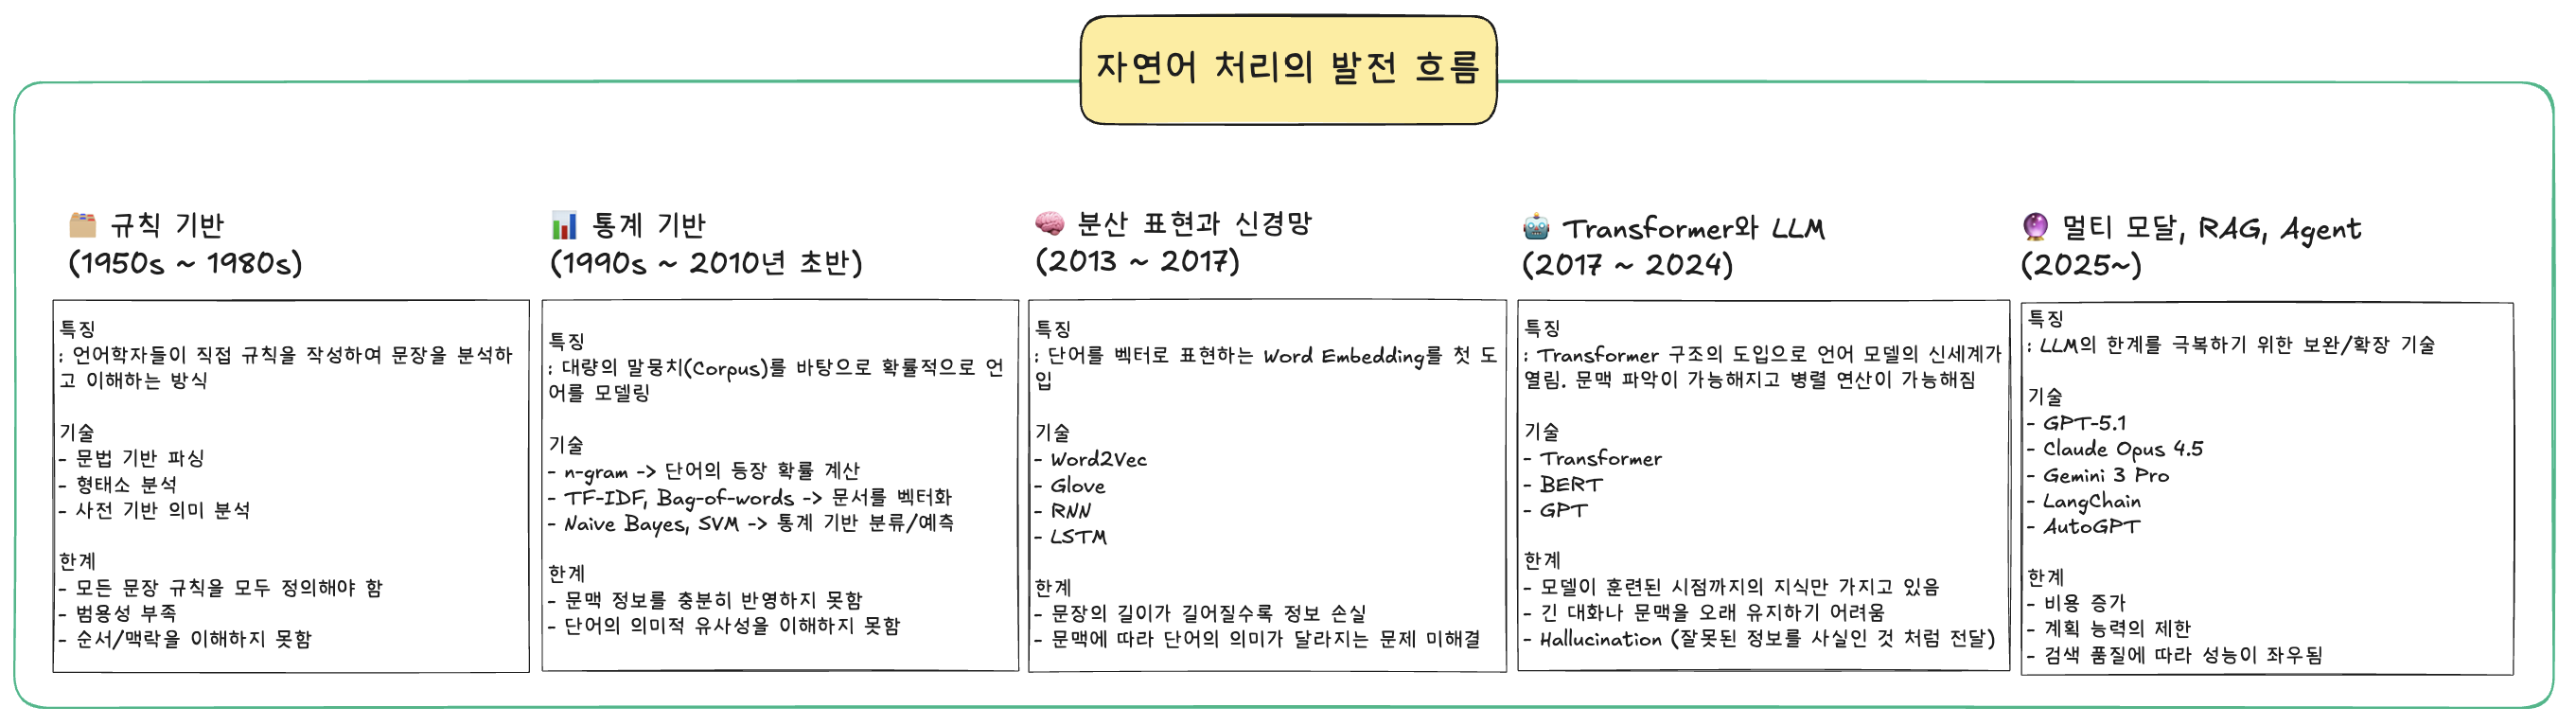

### ✅ 규칙 기반

#### 👍 장점: 특정한 문제에 대해 높은 정확도 가능
#### 👎 단점: 노가다, 일반화 불가능, 순차성, 문맥이해, 단어의 유사성 이해 X

### ✅ 통계 기반

#### 👍 장점: 규칙을 직접 설계할 필요 없음 (처음으로 데이터 기반으로 처리가 가능해짐)
#### 👎 단점: 단어간에 의미적 유사성을 표현하지 못함, 순차성, 맥락 이해 부족

### ✅ 분산 표현 기반

#### 👍 장점: 단어간의 의미적 유사성 표현 가능
#### 👎 단점: 문맥이해, 순차성 부족

### ✅ 딥러닝 기반

#### 👍 장점: 순차적 데이터 처리 가능, 맥락 파악 일부 가능
#### 👎 단점: 글 전체적인 흐름 파악 부족, 병렬 처리 어려움

### ✅ LLM  

#### 👍 장점: 전체 문장의 흐름, 맥락 파악 가능
#### 👎 단점: Hallucination, 학습한 데이터 내에서 답변 가능

### 자연어 처리 작업 분류

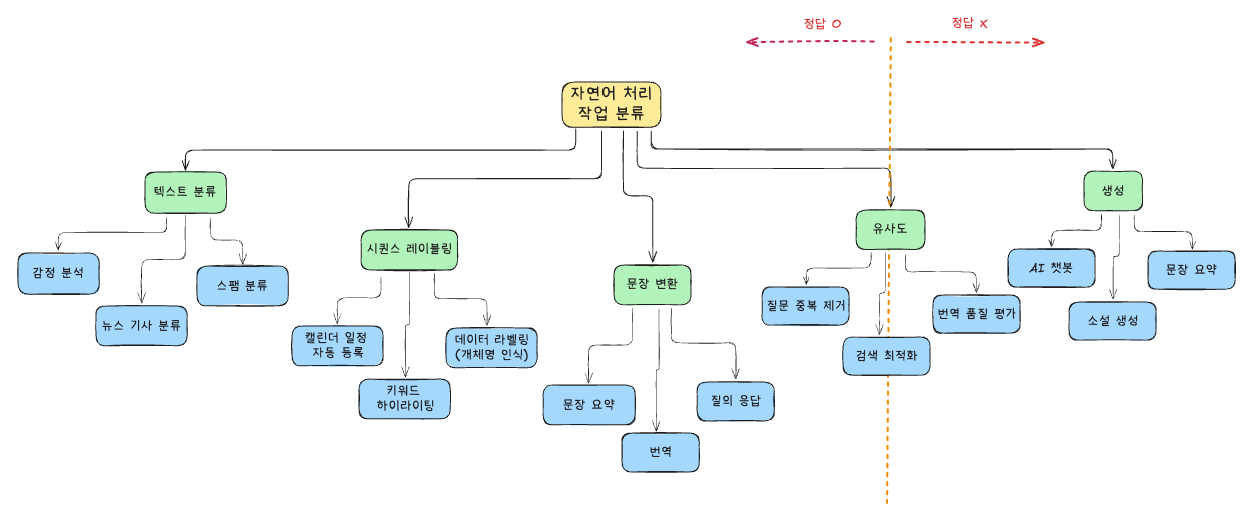

<h1 style="color:orange" id='two'>2. 자연어 데이터의 특징 및 구조</h1>
<a href="#lecture_index">
    <span>⬆ 목차로</span>
</a>

## 자연어 데이터란?
> 사람이 일상생활에서 사용하는 언어. <br>
> 자연어 데이터에는 크게 두 가지 형태로 존재함. 1. 텍스트 2. 음성 <br>
> 예) 한국어, 영어, 일본어, 중국어, 스페인어 등..

### 텍스트 데이터

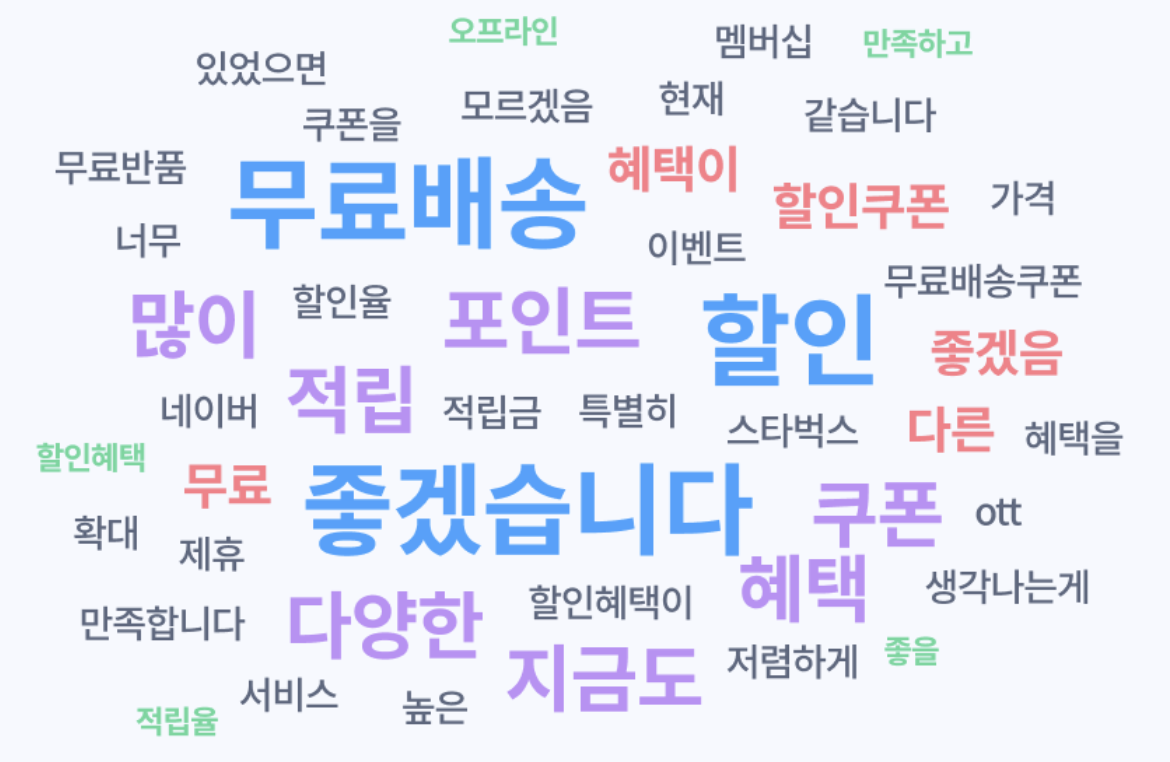

### 음성 데이터

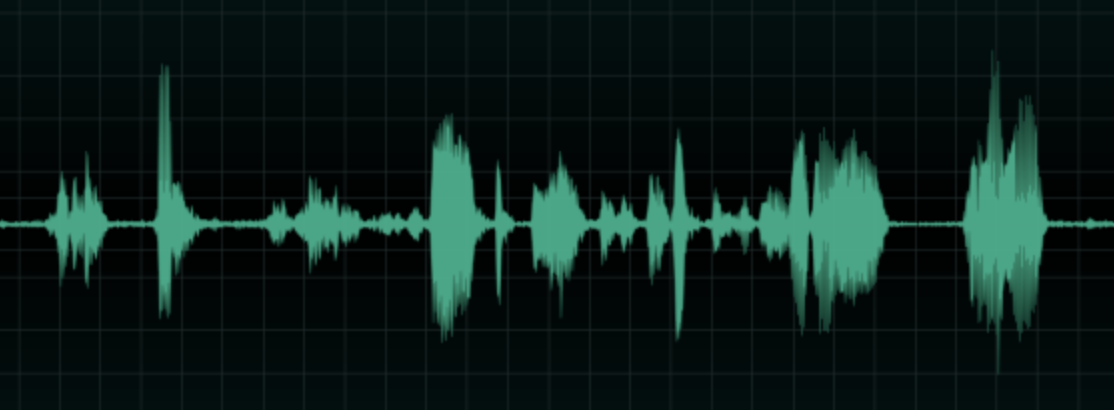

##### 👉 음성 데이터의 형태는 텍스트가 아니라 소리이기 때문에 '파형' 형태를 띈다

### 💡 NLP라는 기술은 텍스트 데이터를 컴퓨터가 이해하고 생성하고 응답하도록 만드는 기술!

## 텍스트 데이터의 특징

### 형태

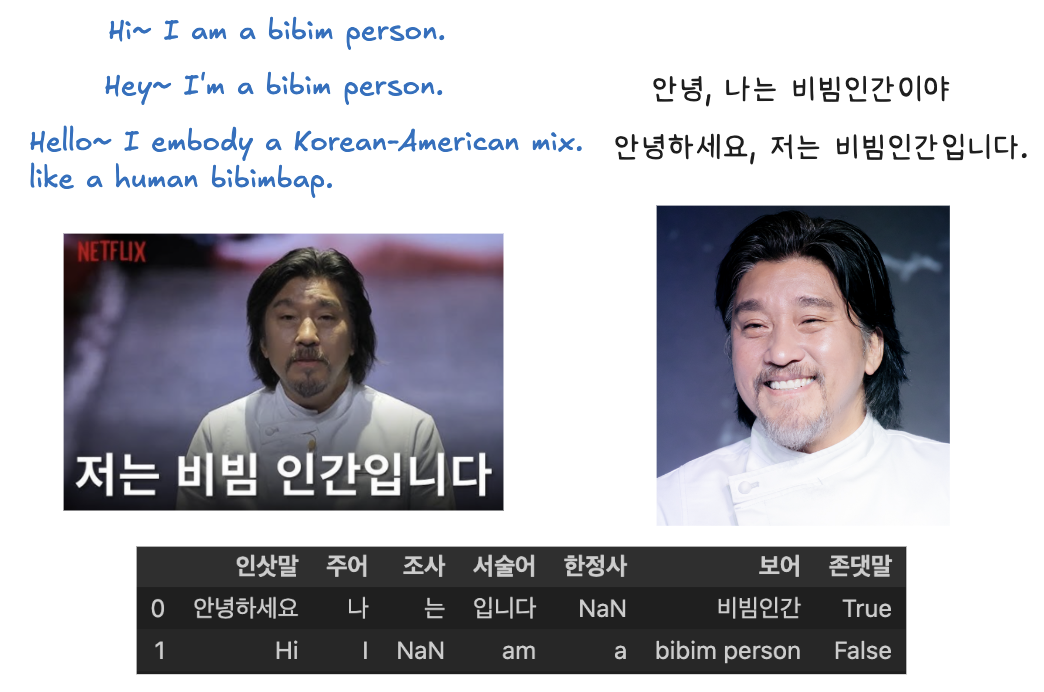

### ① 비정형 데이터
- 테이블 데이터와 다르게 형식이 없음
- 전처리와 정형화 과정이 필수적

### ② 모호성
- 같은 단어라도 상황에 따라 의미가 달라짐
- 동음이의어, 다의어, 문맥 의존성이 존재함

### ③ 다양한 표현 방식
- 같은 의미도 여러 가지 표현 가능
- 동의어, 의미적 유사성 인식이 필요

### ④ 순차성
- 단어의 순서가 중요함
- 순서가 의미에 큰 영향을 주기 때문에 시계열 데이터 처럼 다뤄야 함

### ⑤ 고차원 + 희소성
- 단어를 벡터로 표현하면, 단어 수만큼 차원이 생김 (단어 하나당 하나의 차원으로 표현)
- 예) 단어 사전이 10,000개면 모든 문장은 10,000차원 벡터로 표현
- 한 문장 안에는 그렇게 많은 단어로 이루어져 있지 않음
- 예) 한 문장이 10개 단어로 이루어져 있고, 단어 사전이 10,000개라면 9990개는 0으로 채워지고 10개만 값을 가짐

### ⑥ 문맥 의존성
- 단어의 의미는 주변 단어에 따라 달라짐
- 예) 나는 배가 아파서 병원에 갔다 -> 여기서 '배'는 사람의 신체부위

### ⑦ 언어별 차이
- 언어별로 어순이 다르고 표현하는 글자가 다름
- 한국어의 경우 형태소 분리가 중요함
- 예) 먹었습니다 -> 먹/었/습니다

차원이 너무 많아서 구분하기 힘들어진다 -> 차원의 저주

## 텍스트 데이터 처리 과정

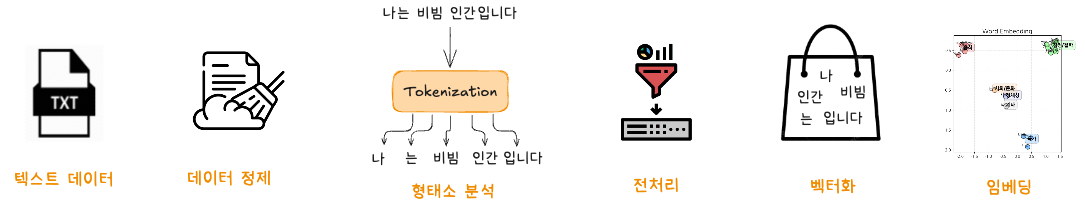

<h1 style="color:orange" id='three'>3. 규칙기반 자연어 처리</h1>
<a href="#lecture_index">
    <span>⬆ 목차로</span>
</a>

### 형태소 분석 및 전처리

> 목적: 문장을 기계가 처리할 수 있는 단위로 표준화 하고 의미 단위로 해석하기 위한 전처리 작업

1. 단어가 어디서 끊기는지 찾고
2. 그 단어가 어떤 역할을 하는지 파악하고 (품사)
3. 필요하면 원형(표제어)로 바꾸고
4. ㅎㅎㅎ, ㅋㅋㅋ, 짱좋다 같은 구어체도 정규화해서 정규화된 표현으로 정리한다

⚠️ 자연어 처리 초반에 사용했던 방식으로 나중에는 형태소 분석과 같이 '문법'을 기준으로 쪼개는 방법 말고, '통계'를 기준으로 쪼개는 새로운 방식을 사용한다

라이브러리|분석기 이름|특징|설치 난이도|
---|---|---|---
KoNLPy|Okt(트위터), Kkma, Hannanum, Komoran, Mecab| 파이썬 인터페이스 지원, 다양한 분석기 통합 제공|⭐️⭐️⭐️⭐️
Mecab|Mecab|매우 빠르고 정확도가 높음. 특히 대용량 텍스트 처리에 적합, 언어 사전 커스터마이징 가능|⭐️⭐️
Khaiii|khaiii|정확도 우수하지만 설치가 복잡|⭐️

분석기 이름|개발 기관|속도|복합어 처리|구어체 처리|신조어 처리|강점
---|---|---|---|---|---|---|
Okt|트위터|⭐️⭐️⭐️⭐️|⭐️⭐️⭐️|⭐️⭐️⭐️⭐️⭐️|⭐️⭐️|SNS, 구어체 처리 특화
Kkma|서울대학교|⭐️|⭐️⭐️⭐️⭐️⭐️|⭐️|⭐️|문장 구조 분석
Hannanum|KAIST|⭐️⭐️⭐️|⭐️|⭐️|⭐️|“정제된 문서 분석”이나 “명사 기반 분석”<br> 처럼 언어적 일관성이 중요한 작업
Komoran|Shineware|⭐️⭐️|⭐️⭐️⭐️⭐️|⭐️⭐️|⭐️⭐️|사용자 사전 추가가 쉬움
Mecab(KoNLPy)|일본 도쿄대 연구원->은전한닢|⭐️⭐️⭐️⭐️⭐️|⭐️⭐️⭐️⭐️⭐️|⭐️⭐️|⭐️⭐️|빠른 속도, 대규모 처리 적합
Khaiii|Kakao|⭐️⭐️|⭐️⭐️⭐️⭐️|⭐️⭐️⭐️|⭐️⭐️⭐️|딥러닝 기반 처리. 품사, 복합어 처리 우수

#### KoNLPy

In [8]:
!pip install konlpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 101.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 495.9/495.9 kB 42.2 MB/s eta 0:00:00


In [9]:
# konlpy 설치하기 전 필요한 설치
# Java 1.8 버전 이상 설치 (java version "1.8.0_441") https://www.oracle.com/java/technologies/downloads/#jdk21-mac
# jpype1 설치 (1.4.1 버전 이상) !pip install JPype1==1.4.1
# konlpy 설치 (0.6.0 버전 이상) !pip install konlpy !uv add konlpy
import konlpy
from konlpy.tag import Okt, Kkma, Hannanum, Komoran, Mecab

### Okt (Open Korean Text)

강점

- SNS, 구어체 처리 특화

https://github.com/open-korean-text/open-korean-text

#### Kkma

강점

- 문장 구조 분석

#### Hannanum

강점

- 명사 추출 성능이 안정적
- 전통적인 언어학 기반 분석에 충실

### 🏷 Hannanum 형태소 태그 정리표

| 태그   | 설명                                | 예시                     |
|--------|-------------------------------------|--------------------------|
| **ncps** | 일반 명사 (단수형)                  | 안녕                     |
| **ncpa** | 행위 명사 (동작 관련 명사)          | 공부                     |
| **npp**  | 대명사                              | 저                       |
| **ncn**  | 일반 명사                           | 인공지능, 요, 재미       |
| **xsms** | 보조용언 어간 (동사)                | 하 (하다의 어간)         |
| **xsva** | 보조용언 어간 (형용사)              | 하 (공부하+고)           |
| **xsmn** | 보조용언 어간 (명사형)              | 있 (재미있어요)          |
| **ecc**  | 연결 어미 (보조적 연결)             | 고 (공부하고)            |
| **ecs**  | 연결 어미 (계속적 연결)             | 고                       |
| **ecx**  | 연결 어미 (혼합형)                  | 고                       |
| **jxc**  | 보조사                              | 는                       |
| **jco**  | 목적격 조사                         | 을                       |
| **ef**   | 종결 어미                           | 어요, 세요               |
| **jxf**  | 종결 보조사                         | 요                       |
| **sf**   | 마침표/느낌표 등 구두점            | ., !                     |
| **sy**   | 기호                                | .                        |
| **jcj**  | 접속 조사                           | 하고                     |
| **jct**  | 시간 연결 조사                      | 하고                     |
| **jcr**  | 이유 연결 조사                      | 고                       |
| **paa**  | 상태 서술 형용사                    | 있                       |
| **px**   | 보조 용언                           | 있                       |
| **pvg**  | 일반 동사                           | 재미있                   |
| **f**    | 외국어 (Foreign)                    | NLP                      |

#### Komoran

강점

- 사용자 사전 추가가 쉬움

### Colab에서 Mecab 사용하기

In [ ]:
!pip install Korpora # 한국어 말뭉치 다운로드용 라이브러리 (설치하면 Java-Python 연결 문제를 어느 정도 해결해줌)

In [ ]:
!git clone https://github.com/SOMJANG/Mecab-ko-for-Google-Colab.git

In [2]:
%cd Mecab-ko-for-Google-Colab/

/content/Mecab-ko-for-Google-Colab


In [ ]:
!bash install_mecab-ko_on_colab_light_220429.sh

### M1 Mac에서 Mecab 사용하기

In [ ]:
!pip install mecab-python
!uv add mecab-python

## 전처리
> 최소 의미 단위로 쪼갠 단어들을 `학습에 적합한 형태`로 다듬는 작업 <br>
> 같은 단어는 같다고 이해할 수 있게, 다른건 다르게 이해할 수 있게 변환 하는 작업. <br>
> 문장을 이해하는데 방해가 되는 불필요한 단어를 제거하기도 한다

- 불용어 처리
- 정규화
- 어간 추출
- 표제어 추출

### 불용어 처리

> 목적: 모델이 핵심 `의미가 있는 단어에 집중`할 수 있게 불필요한 단어를 제거하는 것 <br>
> 상황: 문서 분류 문제 (그러나, 그리고 같은 접속사는 카테고리 구분에 기여하지 않음)

🛠️ 해결하고자 하는 문제에 따라서 남겨야 하는 단어, 제거해야 하는 단어가 달라질 수 있다  <br>
예) 감정 분석 문제 (진짜, 너무, 정말 같은 부사는 불용어가 아닌 감정 표현에 필요한 단어로 제거하지 않음) <br>

🛠️  요즘 LLM 시대에는 불용어를 굳이 제거하지 않는다

#### 정규화
> 목적: 문장 내에 다양한 표현 방식을 `통일된 형태`로 바꾸기 위해 <br>
> 상황: 감성 분석, 키워드 추출, 문서 분류, 신조어, 축약어, 비표준 표현 통합

#### 어간 추출
> 목적: 단어에서 접사, 어미 등 `부가적인 부분을 제거`하고 핵심 어간만 남기는 작업 <br>
> 상황: 감성 분석, 키워드 추출, 문서 분류

#### 표제어 추출
> 목적: 정확한 문법 기반의 단어로 바꾸는 작업 <br>
> 효과: 정확한 단어의 형태를 유지하여 의미를 보존한다 <br>
> 상황: 번역, 질의 응답, 요약 등 정확한 의미 분석

🛠️ 한국어는 `교착어`(조사, 어미가 줄줄이 붙는 구조)라서 단어 형태만으로 의미를 구분하기 힘들다 <br>
따라서, 한국어에서 표제어를 추출하기 위한 `사전은 없다` <br>
단, KAIST에서 구축한 `Korean WordNet`, 부산대학교에서 구축한 `KorLex` 라는 '단어 간의 의미 관계를 체계적으로 정리한 사전'은 존재함

예)
- 먹었습니다
- 먹었어요
- 먹을래요
- 먹고싶어요
- 먹고싶어하지는 않네요 등...

이 모든 형태를 규칙으로 복원하기는 불가능에 가까움

### 감성 분석 (긍정/부정 단어 사전 기반)

### 유사한 문장 판별

### 키워드 추출

## 📝 연습문제

#### 1. 다음 중 규칙 기반 자연어 처리 방식의 활용 예로 적절하지 않은 것은?

```
A. 한글에서 조사(“을”, “를”)를 분리하여 의미 있는 어절을 추출하는 형태소 분석기 개발
B. 의학 도메인에서 사전에 정의된 약어와 전문 용어 사전을 기반으로 임상 기록에서 개체명을 추출하는 시스템
C. 온라인 리뷰에서 ‘재미없다’, ‘별로였다’ 등의 감정을 학습 데이터를 기반으로 자동 분류하는 감성 분석 시스템
D. 특수 기호, 반복 문자, 이모티콘 등을 정규식을 활용하여 제거하는 텍스트 정제기
E. 직접 설계한 문법 규칙으로 날짜 표현을 인식하고 표준화하는 규칙 기반 날짜 인식기
F. 규칙적으로 정의된 이메일 주소, 전화번호 등의 패턴을 정규표현식으로 탐지하고 정제하는 텍스트 필터
G. 뉴스 기사에서 감정이 강하게 나타나는 표현(“충격”, “최악”, “완벽”)의 빈도 수 기반으로 긍/부정을 분류하는 모델
```

#### 2. 다음 문장을 형태소 분석기(tokenizer)를 활용하여 아래 결과 처럼 나오도록 처리하시오

```
분석전: "진짜진짜 이 영화는 너무 너무 별로였어요 ㅠㅠㅠㅠㅠ"
분석후: ['진짜', '영화', '별로', '이다', 'ㅠ']
```

<h1 style="color:orange" id='four'>4. 통계기반 자연어 처리</h1>
<a href="#lecture_index">
    <span>⬆ 목차로</span>
</a>

> 통계 기반 NLP는 `코퍼스`를 통해 단어의 빈도, 동시 발생 빈도 등을 기반으로 처리를 함 <br>
> 💡 통계적 언어 모델의 핵심 아이디어: 단어의 의미는 주변 단어로 알 수 있다

## 텍스트 데이터 단위

<img src="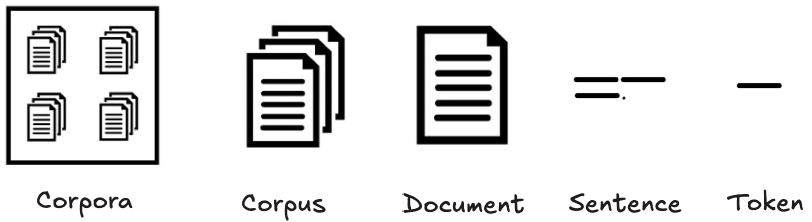
" width="1100" height="350"/>

1. Corpora <br>
: 여러개의 Corpus <br>
예) 다국어 번역 모델 Corpora [영어-한국어 번역 corpus, 한국어-일본어 번역 corpus, 등...]

2. Corpus <br>
: 자연어 문서들의 집합. 모델 학습용으로 수집된 텍스트 데이터 전체. <br>
예) 뉴스 기사 모음, 나무위키 데이터 모음, SNS 글 모음 <br>
⚠️ 단순히 텍스트의 모음이 아니라 품사 태그가 붙거나 텍스트에 라벨이 붙은 데이터도 전부 corpus라 부름 <br>
(raw corpus, annotated corpus, cleaned corpus 등..)

3. Document <br>
: Corpus를 구성하는 개별 문서. <br>
예) 뉴스 기사 하나, 나무위키 검색으로 보이는 페이지 하나, SNS 게시글 하나 <br>

4. Sentence <br>
: Corpus를 구성하는 개별 문장. <br>
  분석 목적에 따라 텍스트를 Document 대신 Sentence 단위로 지정하기도 함 <br>
예) 두 문장의 유사도 분석이 필요한 경우

5. Token <br>
: 문장에서 의미 있는 최소 단위의 단어. <br>
예) "나는 비빔 인간입니다" -> 나, 비빔, 인간, 입니다 또는 나는, 비빔, 인간입니다 등...  <br>
⚠️ 토큰화는 목적에 따라 달라질 수 있음

## Bag of Words

> 문장을 단어의 집합(가방)으로 보고, 순서와 상관 없이 `등장 횟수`만 고려하는 방식 <br>
> 단어 목록을 만들고 이를 기반으로 `문장을 벡터화` 하는 과정까지 포함한다

### ✅ 특징

#### ① 간단하고 빠른 처리가 가능
#### ② 희소(sparse) 벡터가 만들어짐
#### ③ 문맥을 고려하지 않음

BoW 직접 구현하기

### 네이버 영화 리뷰 긍정/부정 분석

### TF-IDF

> Term Frequency - Inverse Document Frequency의 약자로, <br>
> `한 문서` 안에서 `단어가 몇번` 나왔는지, 여러 문서 중 이 단어가 얼마나 희귀한지를 고려하여 데이터를 벡터화함 <br>
> `흔한 단어`는 `가중치를 낮게`, `자주 등장`하는 단어는 `가중치를 높게`

<img src="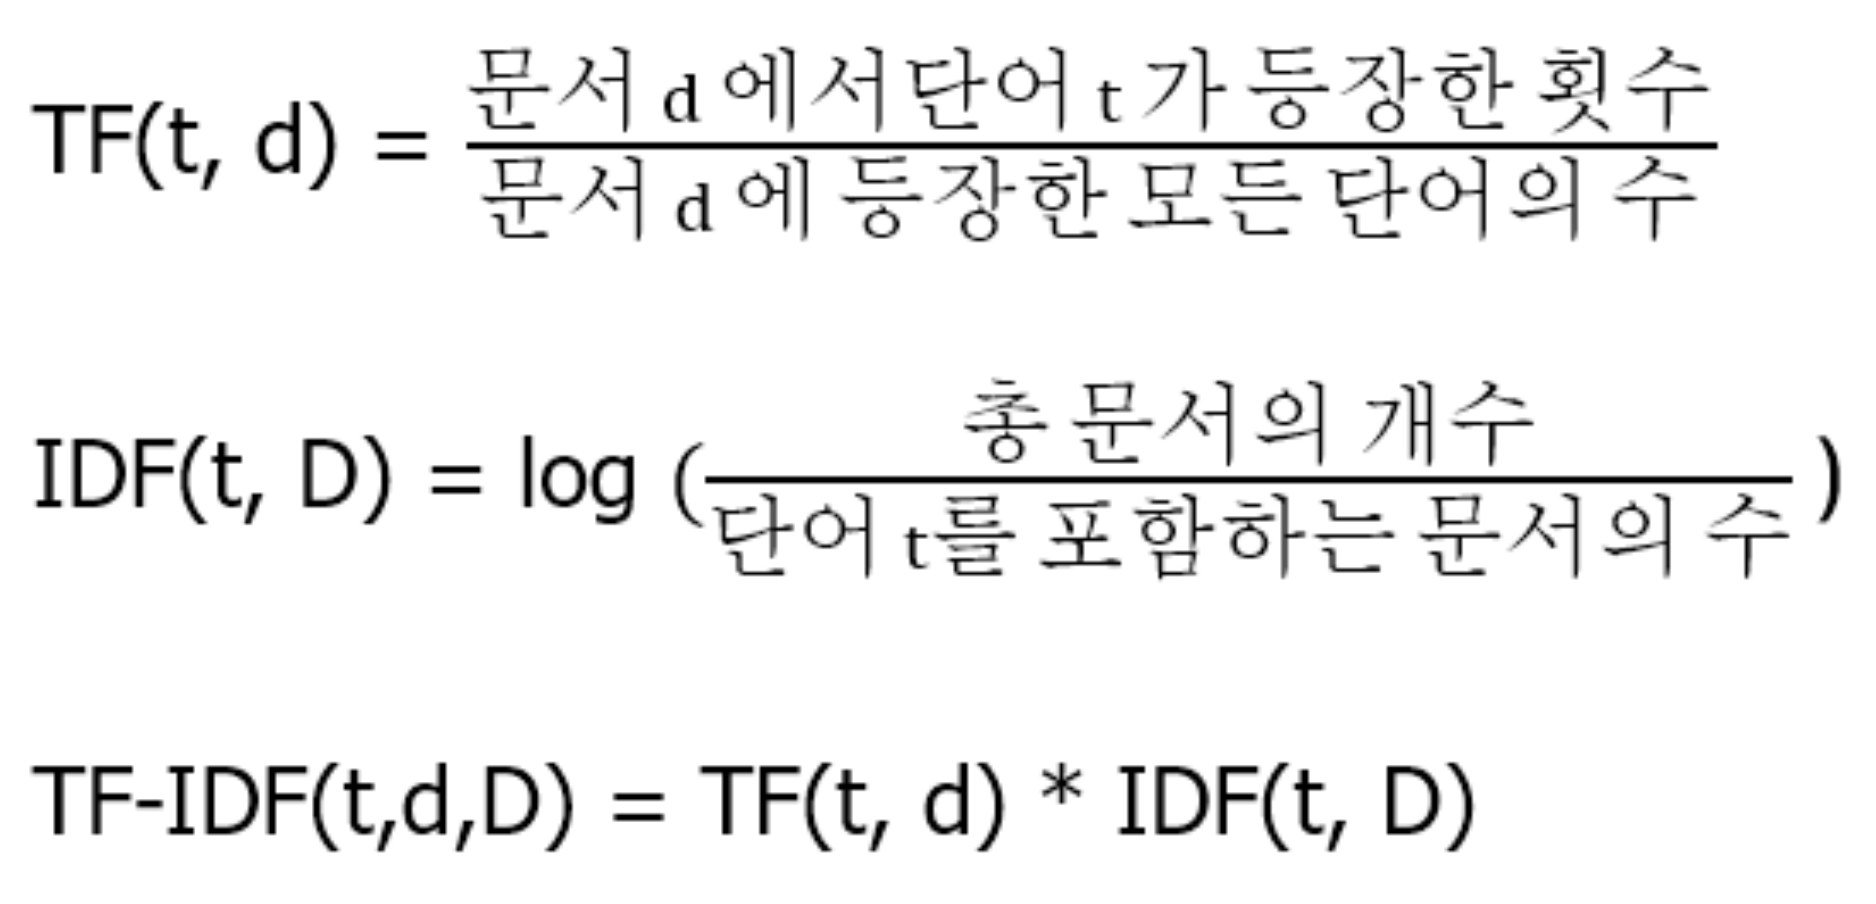
" width="680" height="350"/>

TF: 각 단어가 문장에서 얼마나 중요한가를 나타내는 지표 <br>
IDF: 특정 문서에서만 등장하는 단어가 정보력이 높다는 것을 가정한 지표 <br>

💡 TF-IDF는 한 문장 내에서 많이 등장하면서 다른 문장에서는 잘 등장하지 않는 단어에 높은 점수를 주는 방식

### ✅ 특징

#### ① 단순히 단어의 빈도 뿐만 아니라 전체 문서에서 얼마나 희귀한지도 반영함 <br>
 -> 정보량에 높은 가중치를 줌 (the, a, 은, 는, 이, 가 같이 빈번한 단어는 중요도를 낮게 봄)
#### ② 단어의 등장 위치는 고려하지 않음  
#### ③ 희소(sparse) 벡터가 만들어짐

## 📝 연습문제

문제1. 다음 corpus를 전처리부터 BoW 벡터 생성까지 진행해보세요

1. 전처리 
- 특수문제 제거 
- 반복 문자 축약 
- 불용어 제거 
- 형태소 분석기 활용 
- 감탄사, 불필요한 감정 표현 제거 

2. BoW 벡터 생성 
- CountVectorizer 활용하기
- min_df, max_df를 조절하여 너무 희귀하거나 너무 흔한 단어 제거 

In [ ]:
corpus = [
    "이 영화는 진짜 진짜 너무너무 재미있어요!!! 강추합니다.",
    "영화 스토리는 괜찮았지만 전개가 조금 느리고 지루하더라구요...",
    "배우 연기가 좋아서 전체적인 완성도는 높은 편이에요.",
    "스토리도 배우도 모두 다 훌륭했지만, 결말이 좀 아쉬웠다.",
    "와... 연기력 개쩐다;; 처음부터 끝까지 몰입하면서 봄ㅋㅋㅋㅋ",
    "지루하다기보단 차분한 분위기라서 취향에 따라 호불호가 있을 듯."
]

<h1 style="color:orange" id='five'>5. 분산표현과 신경망</h1>
<a href="#lecture_index">
    <span>⬆ 목차로</span>
</a>

## 분산 표현

> 단어를 `숫자 벡터 공간`안에서 의미있게 배치하는 방법 <br>
> 비슷한 의미의 단어들은 비슷한 위치에, 다른 의미의 단어는 멀리 떨어지도록 학습한 벡터 표현 방법

### 통계 방식의 한계

1. 단어 순서 정보 손실
- BOW 방식은 순서가 사라진다
- 예) “나는 밥을 먹었다”, “밥을 나는 먹었다” -> 둘 다 같은 벡터로 표현함
2. 단어의 의미를 반영하지 못한다
- TF-IDF는 '맛있다', '꿀맛이다'를 전혀 비슷하다고 보지 않음
3. 단어의 관계를 파악할 수 없다
- 통계 방식은 빈도수에 기반한 데이터 이기 때문에 단어간의 관계는 알 수 없음

### 단어간의 유사성을 표현하는 방법

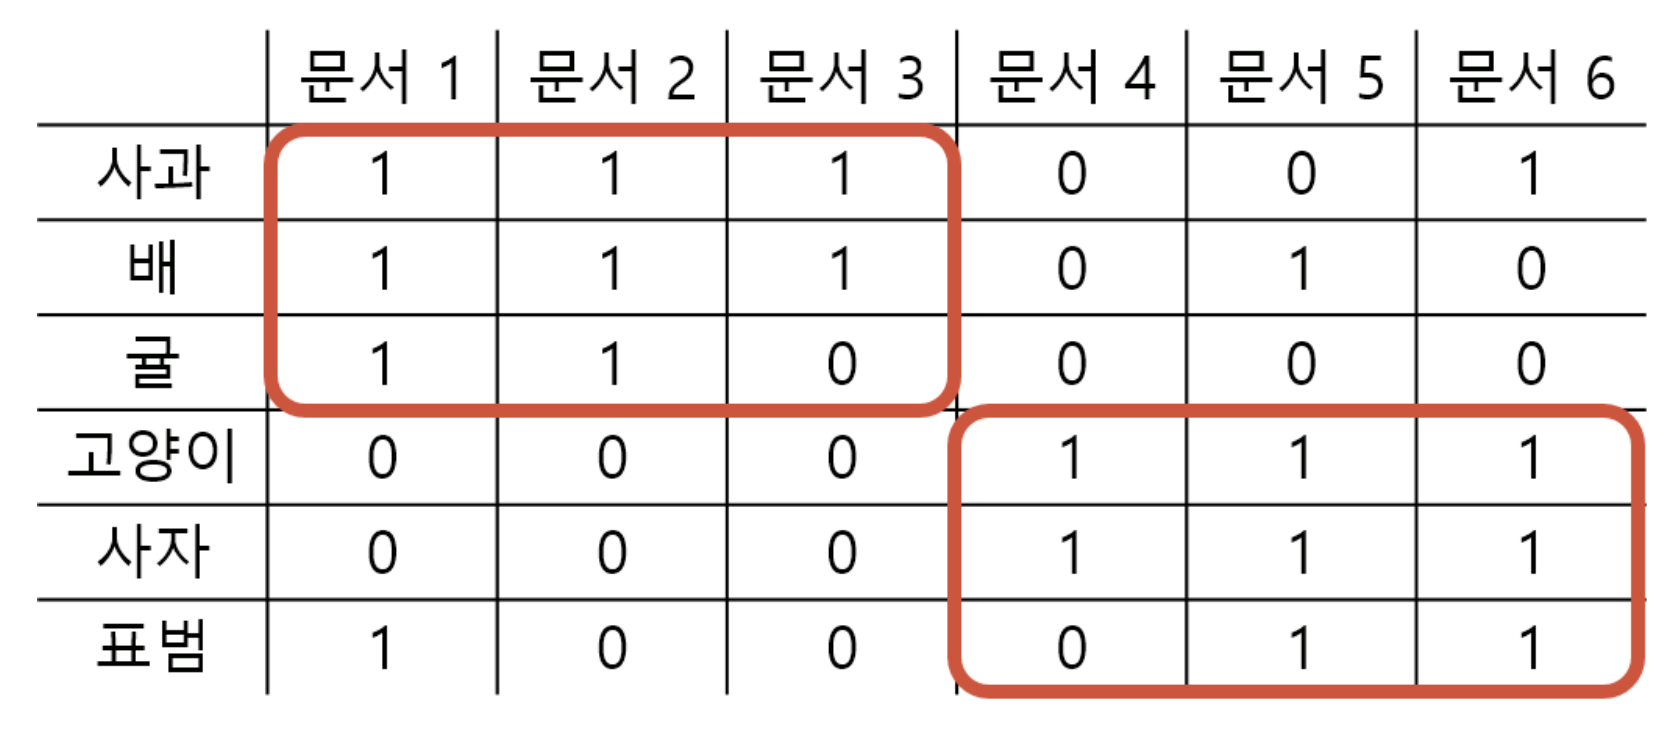

- 위 방식은 여러 문서가 있을 때 단어의 빈도를 통해 단어간의 유사성을 표현할 수는 있음
- 하지만, 단어의 유무로 벡터를 표현하기 때문에 벡터 자체가 단어의 의미를 내포하고 있지는 않음

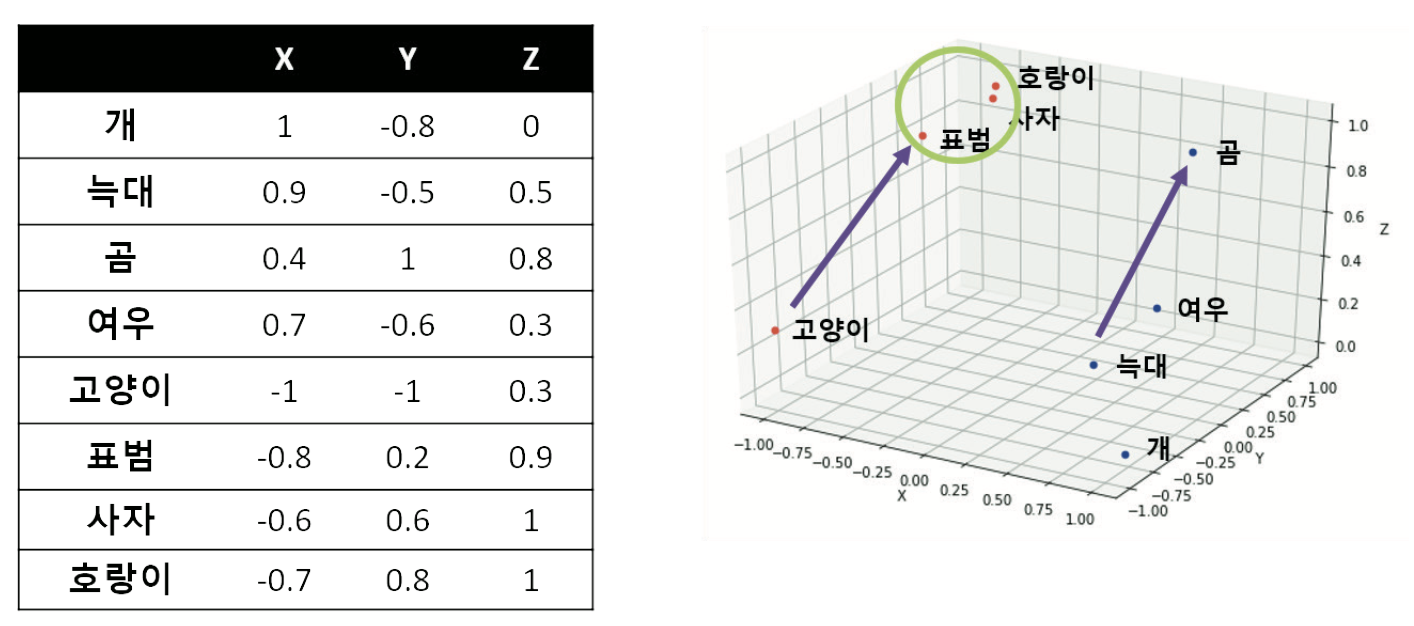

- 각 단어가 3차원 좌표 상의 한 점으로 표현
- 좌표 상의 단순한 숫자(벡터)가 다른 단어와 함께 보면 즉, 문맥으로 보면 의미를 가짐
- 비슷한 문맥에서 사용된 단어들일수록 비슷한 벡터 값을 가지게 됨

#### ✅ Word Embedding이란, 비슷한 의미를 가진 단어들을 비슷한 숫자 벡터로 표현한 결과물.
-> 이 결과물은 많은 텍스트 데이터를 통해 학습하여 만들어진다

### 🧐 어떻게 학습해야 Word Embedding을 만들 수 있는 걸까?

## Word2Vec

> 기존의 희소 벡터 방식의 한계를 극복하기 위해 만들어진 자연어 처리 기법 <br>
> "비슷한 문맥에서 쓰이는 단어는 비슷한 의미를 가진다"는 분포 가설(Distributional Hypothesis)을 가정함 <br>
> 주변 단어로 부터 중심 단어를 예측 하거나, 중심 단어로 부터 주변 단어를 예측하는 방식을 통해 단어를 의미 있는 벡터로 표현한다

<img src="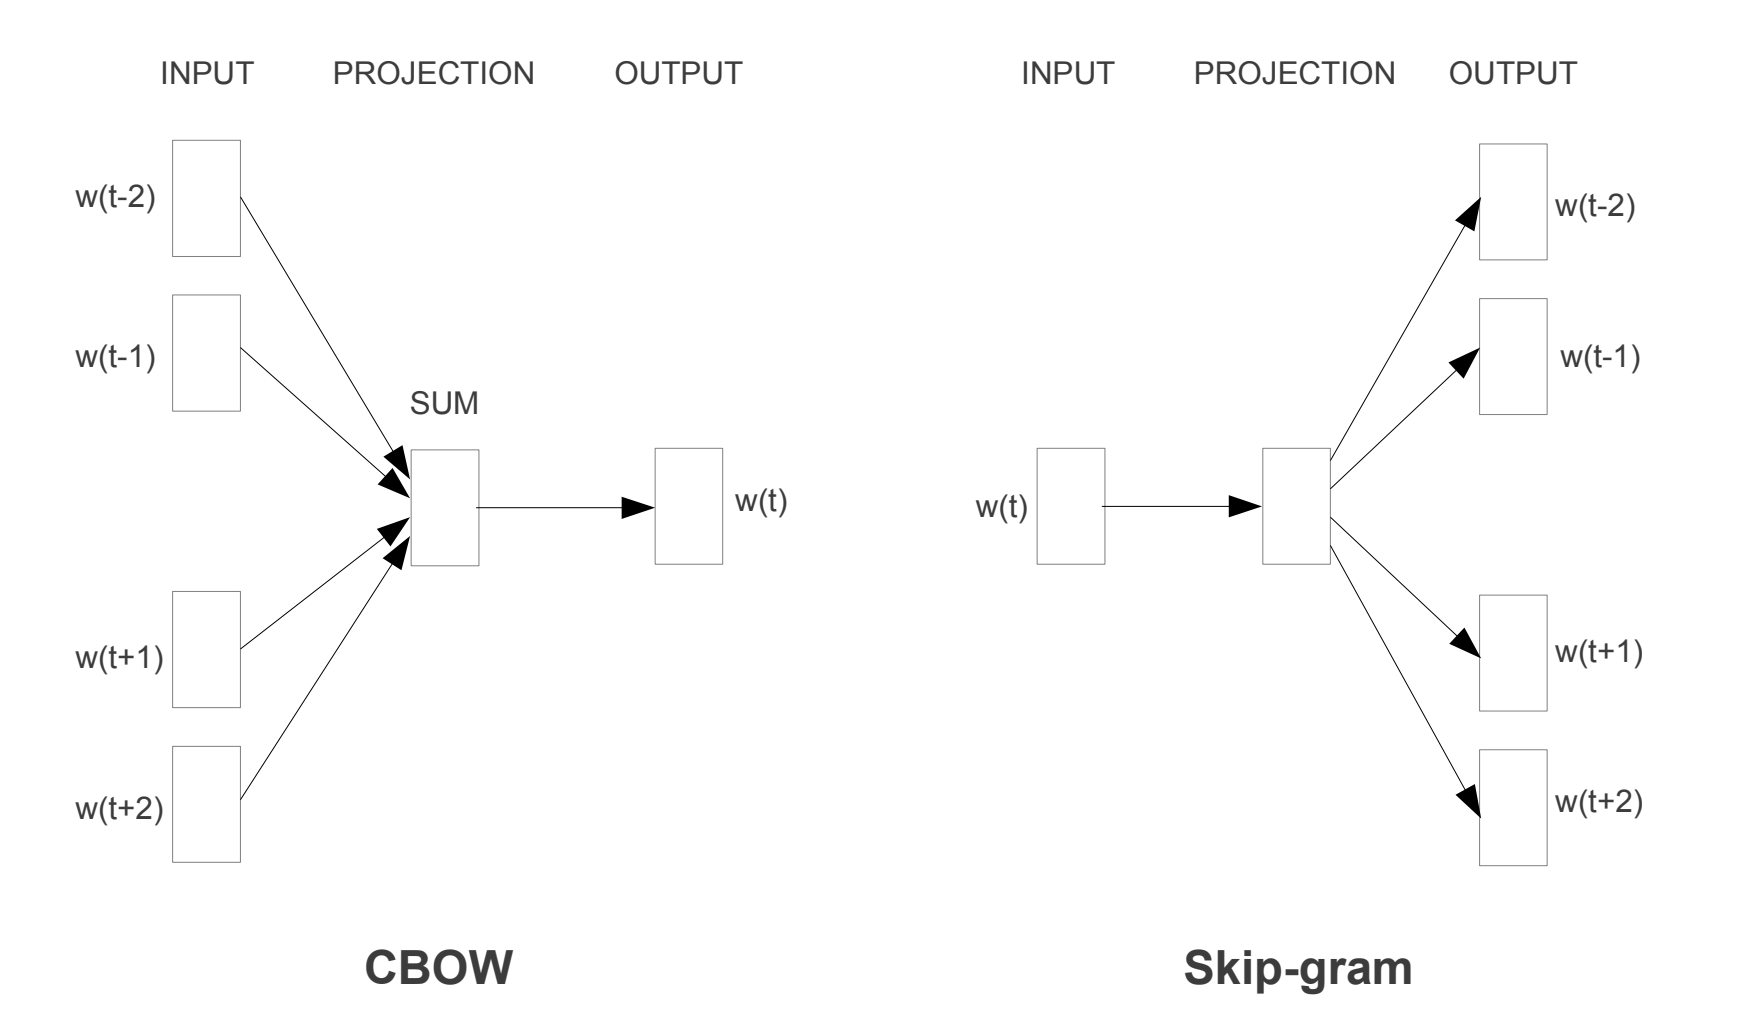
" width="650" height="400"/>

### CBOW (Continuous bag-of-word model)

> 앞 뒤 문맥을 보고 중심 단어를 유추하는 학습 방식

### Skip-gram

> CBOW와 반대. 중심 단어로 부터 이전 단어와 이후 단어를 유추하는 학습 방식